In [2]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from dataset.dataset import load_data
from dataset.utils import *
import matplotlib.pyplot as plt

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cuda:0 NVIDIA GeForce GTX 1650 Ti


In [8]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts



N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing_cards/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing_cards", has_class=False, return_orig=True)

concept_index_to_string = IndexToString("./dataset/playing_cards/attributes.txt")
class_index_to_string = IndexToString("./dataset/playing_cards/classes.txt")

XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=1, use_sigmoid=True)
XtoCtoY.load_state_dict(torch.load("./saves/XtoCtoY_best.pth"))
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

model loaded


## Show true concepts and classification + predicted concepts and classification

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0.])


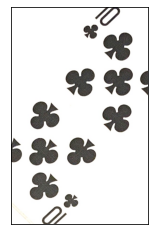

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


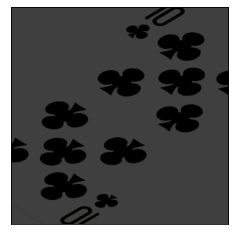

In [9]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [17]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoCtoY(image)

concept_out = prediction[0]
task_out = prediction[1]

_, task_out = task_out.max(1)

pred_concepts_readable = torch.nn.Sigmoid()(concept_out)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
        
print("Class out:", class_index_to_string(task_out.item()))

Predicted concepts: tensor([[0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000,
         0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.7311, 0.5000, 0.7311]],
       device='cuda:0', grad_fn=<SigmoidBackward0>)
id: 0, concept name: Ace, sig value: 0.5
id: 1, concept name: 2, sig value: 0.5
id: 2, concept name: 3, sig value: 0.5
id: 3, concept name: 4, sig value: 0.5
id: 4, concept name: 5, sig value: 0.5
id: 5, concept name: 6, sig value: 0.5
id: 6, concept name: 7, sig value: 0.5
id: 7, concept name: 8, sig value: 0.5
id: 8, concept name: 9, sig value: 0.5
id: 9, concept name: 10, sig value: 0.5
id: 10, concept name: Jack, sig value: 0.5
id: 11, concept name: Queen, sig value: 0.5
id: 12, concept name: King, sig value: 0.5
id: 13, concept name: Hearts, sig value: 0.5
id: 14, concept name: Diamonds, sig value: 0.7310585379600525
id: 15, concept name: Clubs, sig value: 0.5
id: 16, concept name: Spades, sig value: 0.7310585379600525
Class out: Ace_Hearts


# multi card input model


In [20]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts



N_CONCEPT = 52
N_CLASSES = 6
val_loader = load_data("./dataset/individual_three_card_poker/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/individual_three_card_poker", return_orig=True, multi_image=True)

concept_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_classes.txt")
class_index_to_string = IndexToString("./dataset/individual_three_card_poker/hand_classes.txt")

XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=3, use_sigmoid=True)
XtoCtoY.load_state_dict(torch.load("./saves/XtoCtoY_best.pth"))
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

model loaded


True image size (channels, width, height): torch.Size([3, 3, 299, 299])
True  image concepts: tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


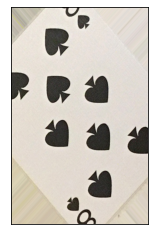

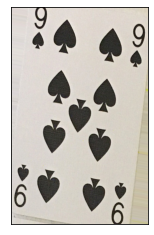

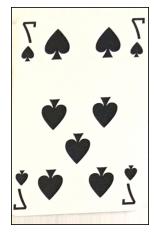

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


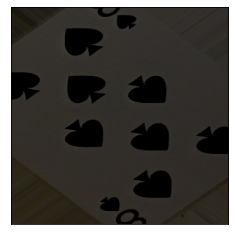

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


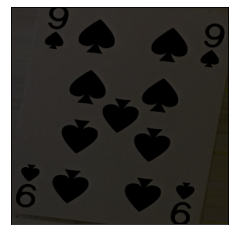

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


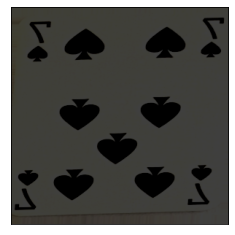

In [21]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

concepts[imageId] = concepts[imageId].view(3, -1)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])


for i in range(images.size(1)):

    plt.xticks([])
    plt.yticks([])
    plt.imshow(original_imgs[imageId][i, :, :, :].squeeze().permute(1, 2, 0))
    plt.show()

for i in range(images.size(1)):

    plt.xticks([])
    plt.yticks([])
    plt.imshow(images[imageId][i, :, :, :].squeeze().permute(1, 2, 0))
    plt.show()

In [22]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoCtoY(image)

concept_out = prediction[0]
task_out = prediction[1]

_, task_out = task_out.max(1)

concept_out = concept_out.view(3, -1)

for i in range(concept_out.size(0)):
    pred_concepts_readable = torch.nn.Sigmoid()(concept_out[i])
    print("Predicted concepts:", pred_concepts_readable)

    # print concept as string if prediction is >= 0.5
    for idx, i in enumerate(pred_concepts_readable):
        if i.item() >= 0.5:
            print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
        
print("Class out:", class_index_to_string(task_out.item()))

Predicted concepts: tensor([    0.0008,     0.0001,     0.0001,     0.1361,     0.0000,     0.0000,
            0.0000,     0.0005,     0.0001,     0.0012,     0.0000,     0.0001,
            0.0007,     0.0000,     0.0002,     0.0005,     0.0000,     0.0335,
            0.0000,     0.0002,     0.2058,     0.0020,     0.0004,     0.0001,
            0.0000,     0.0040,     0.0015,     0.4100,     0.0063,     0.0020,
            0.0000,     0.8480,     0.0010,     0.0000,     0.0000,     0.0000,
            0.0000,     0.0001,     0.0000,     0.0080,     0.0015,     0.0001,
            0.0001,     0.0000,     0.0006,     0.0011,     0.0023,     0.0015,
            0.0010,     0.0001,     0.0002,     0.0001], device='cuda:0',
       grad_fn=<SigmoidBackward0>)
id: 31, concept name: 8S, sig value: 0.8479923009872437
Predicted concepts: tensor([    0.0032,     0.0000,     0.0001,     0.0426,     0.0000,     0.0000,
            0.0000,     0.0000,     0.3540,     0.0376,     0.0000,     0.0